In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, roc_auc_score
)

In [33]:
df = pd.read_csv('ecommerce_customer_data_custom_ratios.csv.zip')

In [34]:
df['Purchase Date'] = pd.to_datetime(
    df['Purchase Date'], errors='coerce'
)

df['Month'] = df['Purchase Date'].dt.month
df['Day'] = df['Purchase Date'].dt.dayofweek


In [35]:
# 4. Remove Unnecessary Columns
df = df.drop(
    columns=['Customer Name', 'Age'],
    errors='ignore'
)

In [36]:
# 5. Remove Missing Target Values
df = df.dropna(subset=['Churn'])

df['Churn'] = df['Churn'].astype(int)

In [37]:
# 6. Check Customer Churn Consistency
churn_counts = df.groupby('Customer ID')['Churn'].nunique()

print("Customers with inconsistent churn labels:",
      (churn_counts > 1).sum())

Customers with inconsistent churn labels: 0


In [38]:
# 7. Create Customer-Level Dataset
consistent_ids = churn_counts[churn_counts == 1].index

df = df[df['Customer ID'].isin(consistent_ids)].copy()

# Separate target before aggregation
y = df.groupby('Customer ID')['Churn'].first()

# Numerical customer features
numeric_features = [
    'Product Price',
    'Quantity',
    'Total Purchase Amount',
    'Customer Age',
    'Returns',
    'Month',
    'Day'
]

# Aggregate transaction data
customer_numeric = df.groupby('Customer ID')[numeric_features].agg(
    ['mean', 'sum', 'count']
)

customer_numeric.columns = [
    '_'.join(col) for col in customer_numeric.columns
]

# Categorical customer features
customer_category = df.groupby('Customer ID')[
    ['Product Category', 'Payment Method', 'Gender']
].agg(lambda x: x.mode().iloc[0] if not x.mode().empty else 'Unknown')

# Combine features
customer_df = customer_numeric.join(customer_category)

customer_df['Churn'] = y

print("\nCustomer-Level Dataset:")
display(customer_df.head())

print("Dataset Shape:", customer_df.shape)



Customer-Level Dataset:


,Product Price_mean,Product Price_sum,Product Price_count,Quantity_mean,Quantity_sum,Quantity_count,Total Purchase Amount_mean,Total Purchase Amount_sum,Total Purchase Amount_count,Customer Age_mean,...,Month_mean,Month_sum,Month_count,Day_mean,Day_sum,Day_count,Product Category,Payment Method,Gender,Churn
Customer ID,,,,,,,,,,,,,,,,,,,,,
1,169.000,169,1,5.000000,5,1,3491.000000,3491,1,70.0,...,7.000000,7,1,2.000000,2,1,Books,PayPal,Male,0
2,140.000,420,3,2.666667,8,3,2662.666667,7988,3,27.0,...,7.666667,23,3,3.333333,10,3,Books,PayPal,Female,0
3,225.375,1803,8,2.875000,23,8,2823.375000,22587,8,23.0,...,7.375000,59,8,3.000000,24,8,Clothing,Credit Card,Female,0
4,134.250,537,4,2.250000,9,4,2178.750000,8715,4,66.0,...,4.500000,18,4,2.250000,9,4,Clothing,Credit Card,Male,1
5,229.000,1832,8,4.125000,33,8,1565.500000,12524,8,26.0,...,6.875000,55,8,1.625000,13,8,Clothing,Credit Card,Female,0


Dataset Shape: (49673, 25)


In [39]:
# 8. Separate Features and Target
X = customer_df.drop(columns=['Churn'])
y = customer_df['Churn']

In [40]:
# 9. Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,
    random_state=42, stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (39738, 24)
Testing Data: (9935, 24)


In [41]:
# 10. Identify Column Types
numeric_cols = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    include=['object', 'category']
).columns.tolist()


In [42]:
# Identify Numerical and Categorical Columns
numeric_cols = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    include=['object', 'category']
).columns.tolist()


# Numerical Preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])


# Categorical Preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])


# Combine Both Preprocessors
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

In [43]:
# 12. Define Models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(
        max_depth=5, random_state=42
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=100, random_state=42
    )
}


In [44]:
# 13. Train and Evaluate Models
results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)

    print("\n================================")
    print("MODEL:", name)
    print("================================")

    print("Accuracy:", round(accuracy, 4))
    print("ROC-AUC:", round(auc, 4))

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'ROC-AUC': auc
    })

    trained_models[name] = pipeline



MODEL: Logistic Regression
Accuracy: 0.7999
ROC-AUC: 0.4953

Classification Report:
              precision    recall  f1-score   support

           0       0.80      1.00      0.89      7947
           1       0.00      0.00      0.00      1988

    accuracy                           0.80      9935
   macro avg       0.40      0.50      0.44      9935
weighted avg       0.64      0.80      0.71      9935

Confusion Matrix:
[[7947    0]
 [1988    0]]

MODEL: Decision Tree
Accuracy: 0.7999
ROC-AUC: 0.4924

Classification Report:
              precision    recall  f1-score   support

           0       0.80      1.00      0.89      7947
           1       0.50      0.00      0.00      1988

    accuracy                           0.80      9935
   macro avg       0.65      0.50      0.44      9935
weighted avg       0.74      0.80      0.71      9935

Confusion Matrix:
[[7946    1]
 [1987    1]]

MODEL: Random Forest
Accuracy: 0.7999
ROC-AUC: 0.4915

Classification Report:
             

In [45]:
# 14. Compare Model Performance
results_df = pd.DataFrame(results)

print("\nCHURN MODEL COMPARISON")
display(results_df.sort_values(by='ROC-AUC', ascending=False))


CHURN MODEL COMPARISON


,Model,Accuracy,ROC-AUC
0,Logistic Regression,0.799899,0.495273
1,Decision Tree,0.799899,0.492413
2,Random Forest,0.799899,0.491499


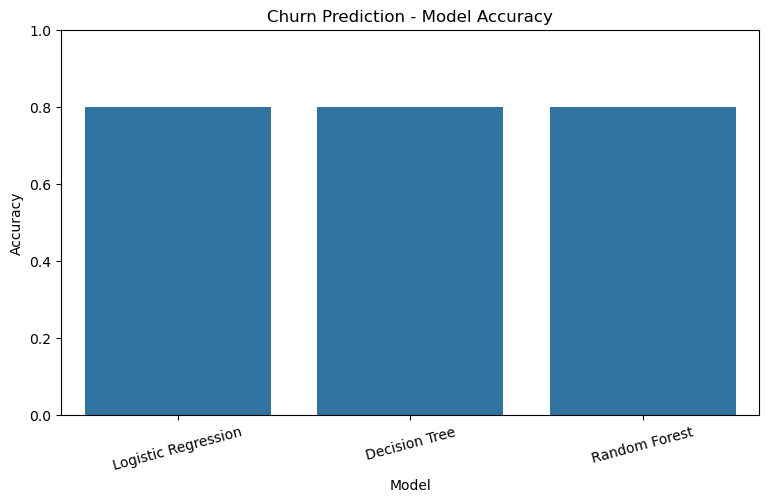

In [46]:
# 15. Visualize Model Accuracy
plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x='Model', y='Accuracy')
plt.title('Churn Prediction - Model Accuracy')
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.show()

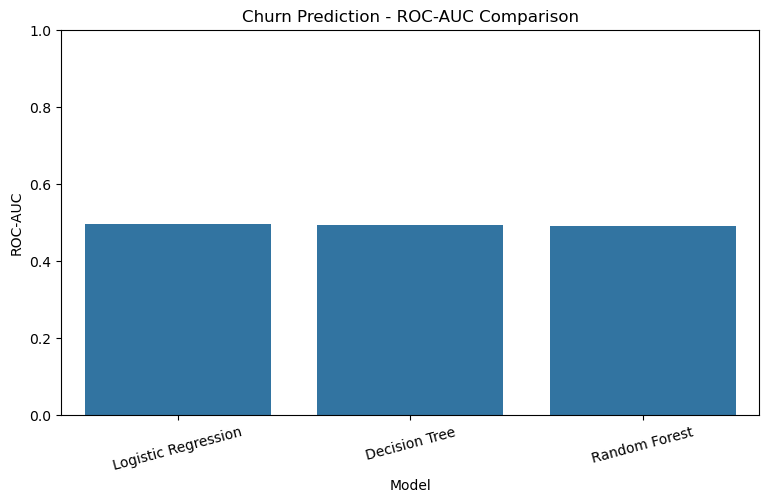

In [47]:
# 16. Visualize ROC-AUC
plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x='Model', y='ROC-AUC')
plt.title('Churn Prediction - ROC-AUC Comparison')
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.show()

In [48]:
# 17. Select Best Model
best_model_name = results_df.sort_values(
    by='ROC-AUC', ascending=False
).iloc[0]['Model']

best_model = trained_models[best_model_name]

print("\nBest Model:", best_model_name)


Best Model: Logistic Regression


In [49]:
# 18. Save All Models and Best Model
os.makedirs('models', exist_ok=True)

for name, model in trained_models.items():
    filename = name.lower().replace(' ', '_')
    joblib.dump(model, f'models/churn_{filename}.pkl')

joblib.dump(best_model, 'models/churn_model.pkl')

print("\nChurn Prediction Models Saved Successfully!")



Churn Prediction Models Saved Successfully!
